# NeuralBandit under Concept Drift: Live Demo

**Reproducing a neural-network bandit committee, then testing uncertainty-aware exploration and shifting-expert selection**

[GitHub](https://github.com/rchelwng/neuralbandit-plus) | Original paper: Allesiardo et al., 2014 ([arXiv 1409.8191](https://arxiv.org/abs/1409.8191))

---

## The problem:
A **contextual bandit** must make a choice for each incoming case and only learns whether *that* choice was right,
never what the right answer would have been. Think of a recommender that shows one ad and only sees whether it was clicked.

Here each case is a patch of forest (Forest Cover Type data), the choice is one of 7 tree-cover types, and the
reward is 1 if the pick is correct. Real-world tastes change over time, so halfway through the labels **rotate**:
this is **concept drift**, and everything each method learned is suddenly wrong.

## What this demo shows:
The code from our project, running live: four methods see the same stream of cases, with **one** drift.

| Method | What it is |
|---|---|
| **LinUCB** | Standard linear bandit baseline |
| **NB2** | The paper's method: a committee of 15 neural networks, with a manager (EXP3) that picks which network to trust each round |
| **NB2 + EXP3.S** (our Hypothesis 2, H2) | Manager keeps a small weight on every network, so it can switch to a better one after a drift |
| **NB2 + MCD-TS** (our Hypothesis 1, H1) | Explores using the networks' own uncertainty (MC dropout) instead of at random |

**What to watch for:** how far each method drops at the drift, and how quickly it climbs back.

## What it does and does not prove:
- ✅ **It shows the paper's main point in action:** the linear method collapses at the drift and recovers slowly, while the neural committees drop less and partially recover, so they end with less regret.
- ✅ **It shows the pipeline works end to end** on real data: anyone can rerun it from this notebook.
- ⚠️ **It is one short run, so it is an illustration**. It cannot reliably rank NB2, EXP3.S and MC dropout: their differences are small, and a single run can make any of them look best. Those claims come from **10 runs of 2.5 million rounds** with confidence intervals and statistical tests (see the paper and `results/REPORT.md`).

---

In [5]:
#@title **1 · Set up** (about 1 minute)
import os
if not os.path.isdir("/content/neuralbandit-plus"):
    !git clone -q https://github.com/rchelwng/neuralbandit-plus.git /content/neuralbandit-plus
%cd /content/neuralbandit-plus
!pip install -q -r requirements.txt
print("✅ Code and packages ready" if os.path.exists("requirements.txt") else "❌ Download failed: check the repo is public")

/content/neuralbandit-plus
✅ Code and packages ready


In [6]:
#@title **2 · Prepare Covertype data** (1-2 minutes, once)
import os
if os.path.exists("data/covtype.npz"):
    print("✅ Covertype already prepared")
else:
    !python scripts/prepare_data.py covtype

✅ Covertype already prepared


✔ LinUCB finished in 3s
✔ NB2 finished in 36s
✔ NB2+EXP3.S finished in 35s
✔ NB2+MCD-TS finished in 53s


### Results: 200,000 rounds, drift every 100,000

,Accuracy,Cumulative regret,Runtime (s)
Method,,,
LinUCB,53.5%,"92,914",3
NB2,60.9%,"78,205",36
NB2+EXP3.S,61.4%,"77,160",35
NB2+MCD-TS,62.2%,"75,585",53


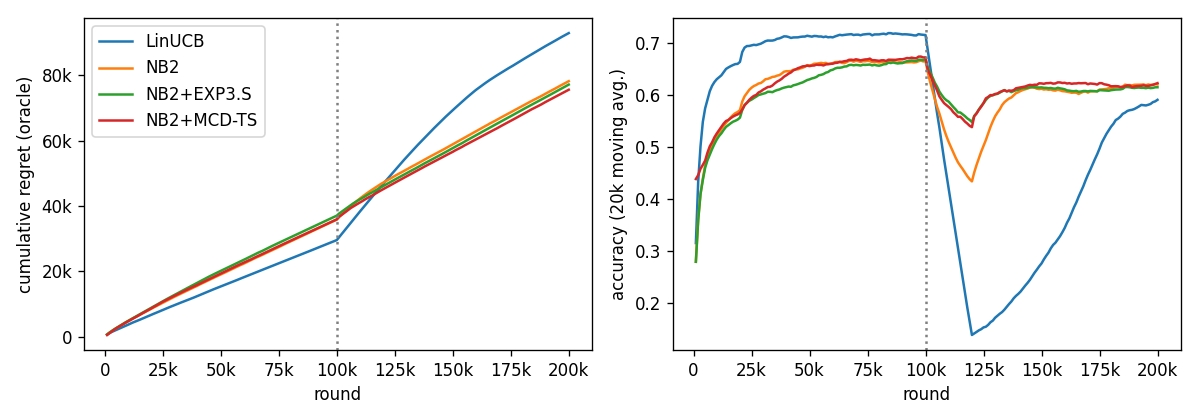

In [10]:
#@title **3 · Run the demo** (about 2 minutes)
rounds = 200000       #@param {type:"integer"}
drift_every = 100000  #@param {type:"integer"}

import re, subprocess, sys
import pandas as pd
from IPython.display import Image, display, Markdown

rows = []
proc = subprocess.Popen([sys.executable, "scripts/demo.py", "--T", str(rounds), "--period", str(drift_every)],
                        stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
for line in proc.stdout:
    m = re.match(r"(\S+)\s+accuracy ([\d.]+)\s+oracle regret\s+([\d,]+)\s+([\d.]+)s", line)
    if m:
        name, acc, reg, sec = m.groups()
        print(f"✔ {name} finished in {float(sec):.0f}s", flush=True)
        rows.append({"Method": name, "Accuracy": f"{float(acc):.1%}",
                     "Cumulative regret": reg, "Runtime (s)": f"{float(sec):.0f}"})
    elif "saved" not in line:
        print(line, end="")
proc.wait()

display(Markdown(f"### Results: {rounds:,} rounds, drift every {drift_every:,}"))
display(pd.DataFrame(rows).set_index("Method"))
display(Image("demo.png", width=1000))

## How to interpret the results:
- **Dotted line** = the drift (labels rotate).
- **Left, cumulative regret:** total mistakes so far compared with a perfect predictor. *Lower is better*; a steeper line means more mistakes per round.
- **Right, accuracy** over the last 20,000 rounds. A drop is the drift hitting; climbing back is the method relearning.

**Typical picture:**
1. **Before the drift**, LinUCB is competitive or slightly ahead: the committees are still learning (they need a few hundred thousand rounds to settle).
2. **At the drift**, LinUCB falls below random guessing, because it keeps confidently predicting the old labels, and it recovers slowly because it never forgets old data.
3. **The committees** drop much less and climb back part of the way within tens of thousands of rounds.
4. **Result:** LinUCB's regret line bends upward and overtakes the committees.

**About the three NB2 lines:** they may overlap or differ a little in a single run (for example, one may dip further at the drift). Don't read a ranking into that: one short run is noisy. Over the full 10-run experiments on Covertype, EXP3.S lowered NB2's regret by about 4%, and MC dropout did **not** help (it raised regret by about 6%).